# UC CosMx RNA + protein: processing

UC sections of the CosMx RNA + protein run (64-antibody panel). The figure uses section 385R_381R (`RNA1_Cos4_385R_381R_S2_norm_wpr_anno_jd.h5ad`).

1. Load RNA and protein objects; keep protein cells that are in the RNA object.
2. RNA QC (counts, genes, cell area) and total-count normalisation; export normalised counts for AUCell (`01_uc_rna_aucell_annotation.R`; the two sections are `Cos4_UC_M_batch1_S2` and `Cos4_UC_M_batch2_S2` there).
3. Attach the AUCell labels and the cell-type name map.
4. Protein: log1p and per-protein centring (columns without suffix) and per-cell geometric-mean centring (`_geo` columns), added to `.obs`.
5. Write the RNA objects with protein in `.obs`.

**Output:** `RNA1_Cos4_385R_381R_S2_norm_wpr_anno_jd.h5ad`, `RNA1_Cos4_322R_367R_S2_norm_wpr_anno_jd.h5ad` (input of `05`).

In [1]:
import scanpy as sc
import pandas as pd
import numpy as np
import squidpy as sq
import matplotlib.pyplot as plt
import seaborn as sns
import os
import scipy.stats as stats


/data/ydn4687/.conda/envs/geneformer/lib/python3.10/site-packages/requests/__init__.py:109: RequestsDependencyWarning: urllib3 (2.2.3) or chardet (5.2.0)/charset_normalizer (None) doesn't match a supported version!
  warnings.warn(
/data/ydn4687/.conda/envs/geneformer/lib/python3.10/site-packages/numba/core/decorators.py:246: RuntimeWarning: nopython is set for njit and is ignored
  warnings.warn('nopython is set for njit and is ignored', RuntimeWarning)


In [2]:
load_PATH = "/share/fsmresfiles/UC/scOmics_model/data/Spatial_Protein_CosMx"

In [3]:

RNA1 = sc.read_h5ad(f"{load_PATH}/RNA1_Cos4_385R_381R_S2.h5ad")
Pro1_raw = sc.read_h5ad(f"{load_PATH}/Pro1_Cos4_385R_381R_S2.h5ad")
RNA2 = sc.read_h5ad(f"{load_PATH}/RNA2_Cos4_322R_367R_S4.h5ad")
Pro2_raw = sc.read_h5ad(f"{load_PATH}/Pro2_Cos4_322R_367R_S4.h5ad")


In [4]:
Pro1 = Pro1_raw[Pro1_raw.obs['cell'].isin(RNA1.obs['cell'])]
Pro2 = Pro2_raw[Pro2_raw.obs['cell'].isin(RNA2.obs['cell'])]
 

In [32]:
RNA1

AnnData object with n_obs × n_vars = 15177 × 6175
    obs: 'fov', 'Area', 'AspectRatio', 'Width', 'Height', 'Mean.PanCK', 'Max.PanCK', 'Mean.CD3', 'Max.CD3', 'Mean.Membrane', 'Max.Membrane', 'Mean.CD45', 'Max.CD45', 'Mean.DAPI', 'Max.DAPI', 'cell_id', 'X', 'version', 'dualfiles', 'Run_name', 'Run_Tissue_name', 'ISH.concentration', 'Dash', 'tissue', 'Panel', 'assay_type', 'slide_ID', 'cell_ID', 'unassignedTranscripts', 'median_RNA', 'RNA_quantile_0.75', 'RNA_quantile_0.8', 'RNA_quantile_0.85', 'RNA_quantile_0.9', 'RNA_quantile_0.95', 'RNA_quantile_0.99', 'nCount_RNA', 'nFeature_RNA', 'median_negprobes', 'negprobes_quantile_0.75', 'negprobes_quantile_0.8', 'negprobes_quantile_0.85', 'negprobes_quantile_0.9', 'negprobes_quantile_0.95', 'negprobes_quantile_0.99', 'nCount_negprobes', 'nFeature_negprobes', 'median_falsecode', 'falsecode_quantile_0.75', 'falsecode_quantile_0.8', 'falsecode_quantile_0.85', 'falsecode_quantile_0.9', 'falsecode_quantile_0.95', 'falsecode_quantile_0.99', 'nCount_

In [17]:
RNA2

AnnData object with n_obs × n_vars = 49287 × 6175
    obs: 'fov', 'Area', 'AspectRatio', 'Width', 'Height', 'Mean.PanCK', 'Max.PanCK', 'Mean.CD3', 'Max.CD3', 'Mean.Membrane', 'Max.Membrane', 'Mean.CD45', 'Max.CD45', 'Mean.DAPI', 'Max.DAPI', 'cell_id', 'X', 'version', 'dualfiles', 'Run_name', 'Run_Tissue_name', 'ISH.concentration', 'Dash', 'tissue', 'Panel', 'assay_type', 'slide_ID', 'cell_ID', 'unassignedTranscripts', 'median_RNA', 'RNA_quantile_0.75', 'RNA_quantile_0.8', 'RNA_quantile_0.85', 'RNA_quantile_0.9', 'RNA_quantile_0.95', 'RNA_quantile_0.99', 'nCount_RNA', 'nFeature_RNA', 'median_negprobes', 'negprobes_quantile_0.75', 'negprobes_quantile_0.8', 'negprobes_quantile_0.85', 'negprobes_quantile_0.9', 'negprobes_quantile_0.95', 'negprobes_quantile_0.99', 'nCount_negprobes', 'nFeature_negprobes', 'median_falsecode', 'falsecode_quantile_0.75', 'falsecode_quantile_0.8', 'falsecode_quantile_0.85', 'falsecode_quantile_0.9', 'falsecode_quantile_0.95', 'falsecode_quantile_0.99', 'nCount_

In [18]:
rna1_qc = RNA1.copy()
rna2_qc = RNA2.copy()

In [19]:
sc.pp.calculate_qc_metrics(
    rna1_qc, inplace=True, log1p=True
)

In [25]:
sc.pp.calculate_qc_metrics(
    rna2_qc, inplace=True, log1p=True
)

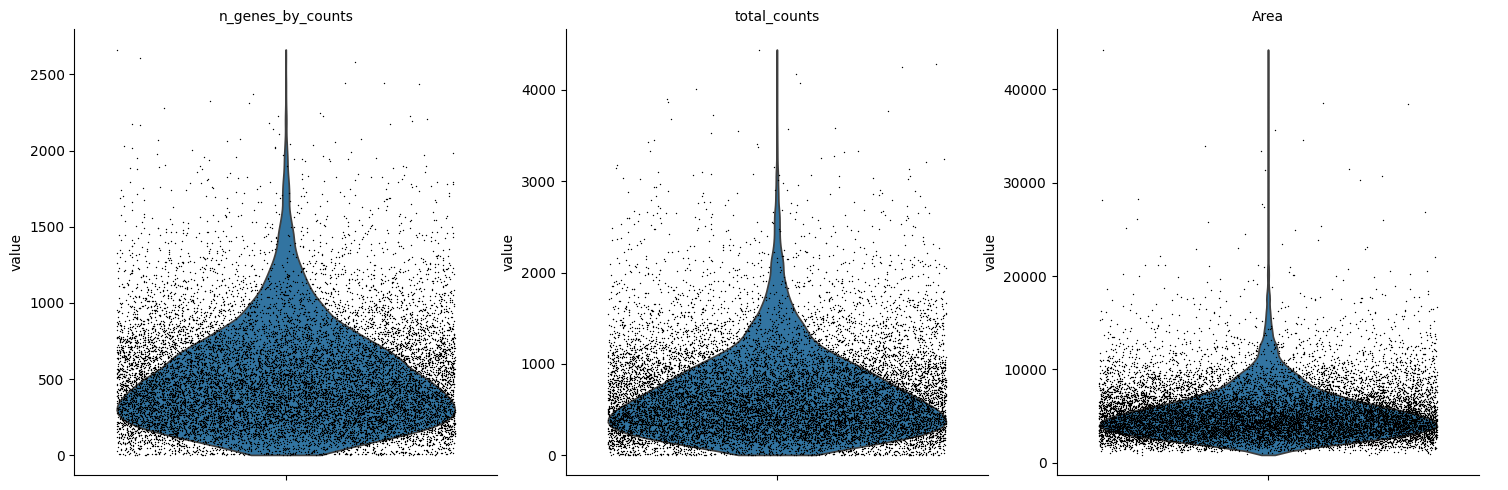

In [20]:
sc.pl.violin(
    rna1_qc,
    ["n_genes_by_counts", "total_counts",'Area'],
    jitter=0.4,
    multi_panel=True,
)

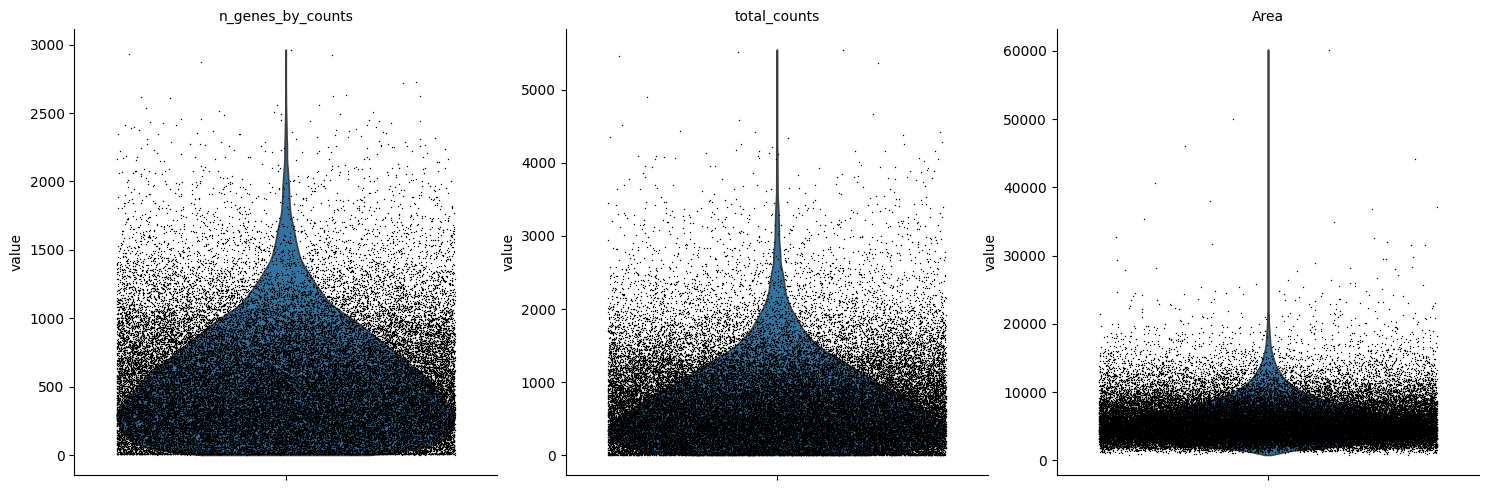

In [26]:
sc.pl.violin(
    rna2_qc,
    ["n_genes_by_counts", "total_counts",'Area'],
    jitter=0.4,
    multi_panel=True,
)

In [21]:
# only remove cells that have too little gene counts
sc.pp.filter_cells(rna1_qc, min_counts=200)
sc.pp.filter_cells(rna1_qc, min_genes=100)
sc.pp.filter_cells(rna1_qc, max_counts=4000)
sc.pp.filter_cells(rna1_qc, max_genes=2500)
rna1_qc=rna1_qc[rna1_qc.obs['Area']<=30000]

In [27]:
# only remove cells that have too little gene counts
sc.pp.filter_cells(rna2_qc, min_counts=200)
sc.pp.filter_cells(rna2_qc, min_genes=100)
sc.pp.filter_cells(rna2_qc, max_counts=4000)
sc.pp.filter_cells(rna2_qc, max_genes=2500)
rna2_qc=rna2_qc[rna2_qc.obs['Area']<=30000]

In [22]:
rna1_qc

View of AnnData object with n_obs × n_vars = 13415 × 6175
    obs: 'fov', 'Area', 'AspectRatio', 'Width', 'Height', 'Mean.PanCK', 'Max.PanCK', 'Mean.CD3', 'Max.CD3', 'Mean.Membrane', 'Max.Membrane', 'Mean.CD45', 'Max.CD45', 'Mean.DAPI', 'Max.DAPI', 'cell_id', 'X', 'version', 'dualfiles', 'Run_name', 'Run_Tissue_name', 'ISH.concentration', 'Dash', 'tissue', 'Panel', 'assay_type', 'slide_ID', 'cell_ID', 'unassignedTranscripts', 'median_RNA', 'RNA_quantile_0.75', 'RNA_quantile_0.8', 'RNA_quantile_0.85', 'RNA_quantile_0.9', 'RNA_quantile_0.95', 'RNA_quantile_0.99', 'nCount_RNA', 'nFeature_RNA', 'median_negprobes', 'negprobes_quantile_0.75', 'negprobes_quantile_0.8', 'negprobes_quantile_0.85', 'negprobes_quantile_0.9', 'negprobes_quantile_0.95', 'negprobes_quantile_0.99', 'nCount_negprobes', 'nFeature_negprobes', 'median_falsecode', 'falsecode_quantile_0.75', 'falsecode_quantile_0.8', 'falsecode_quantile_0.85', 'falsecode_quantile_0.9', 'falsecode_quantile_0.95', 'falsecode_quantile_0.99', 

In [28]:
rna2_qc

View of AnnData object with n_obs × n_vars = 41420 × 6175
    obs: 'fov', 'Area', 'AspectRatio', 'Width', 'Height', 'Mean.PanCK', 'Max.PanCK', 'Mean.CD3', 'Max.CD3', 'Mean.Membrane', 'Max.Membrane', 'Mean.CD45', 'Max.CD45', 'Mean.DAPI', 'Max.DAPI', 'cell_id', 'X', 'version', 'dualfiles', 'Run_name', 'Run_Tissue_name', 'ISH.concentration', 'Dash', 'tissue', 'Panel', 'assay_type', 'slide_ID', 'cell_ID', 'unassignedTranscripts', 'median_RNA', 'RNA_quantile_0.75', 'RNA_quantile_0.8', 'RNA_quantile_0.85', 'RNA_quantile_0.9', 'RNA_quantile_0.95', 'RNA_quantile_0.99', 'nCount_RNA', 'nFeature_RNA', 'median_negprobes', 'negprobes_quantile_0.75', 'negprobes_quantile_0.8', 'negprobes_quantile_0.85', 'negprobes_quantile_0.9', 'negprobes_quantile_0.95', 'negprobes_quantile_0.99', 'nCount_negprobes', 'nFeature_negprobes', 'median_falsecode', 'falsecode_quantile_0.75', 'falsecode_quantile_0.8', 'falsecode_quantile_0.85', 'falsecode_quantile_0.9', 'falsecode_quantile_0.95', 'falsecode_quantile_0.99', 

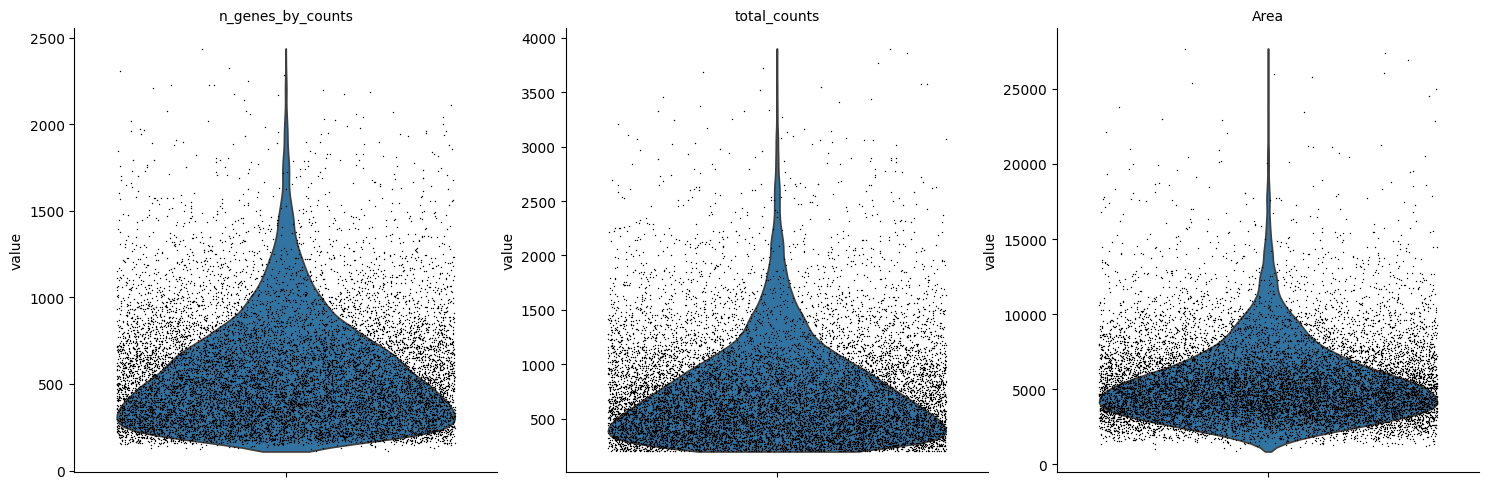

In [23]:
sc.pl.violin(
    rna1_qc,
    ["n_genes_by_counts", "total_counts",'Area'],
    jitter=0.4,
    multi_panel=True,
)

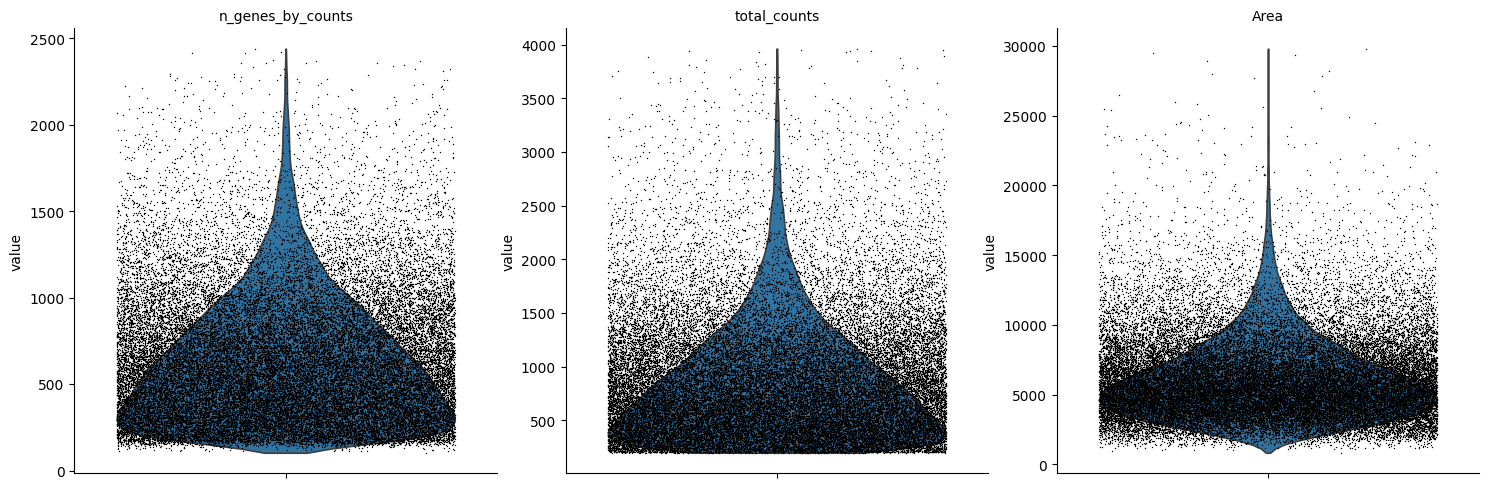

In [29]:
sc.pl.violin(
    rna2_qc,
    ["n_genes_by_counts", "total_counts",'Area'],
    jitter=0.4,
    multi_panel=True,
)

In [34]:
rna1_qc.layers['raw']=pd.DataFrame(rna1_qc.X)
rna2_qc.layers['raw']=pd.DataFrame(rna2_qc.X)

/tmp/ipykernel_651608/208445276.py:1: ImplicitModificationWarning: Setting element `.layers['raw']` of view, initializing view as actual.
  rna1_qc.layers['raw']=pd.DataFrame(rna1_qc.X)
/tmp/ipykernel_651608/208445276.py:2: ImplicitModificationWarning: Setting element `.layers['raw']` of view, initializing view as actual.
  rna2_qc.layers['raw']=pd.DataFrame(rna2_qc.X)


In [35]:
sc.pp.normalize_total(rna1_qc, inplace=True)
sc.pp.normalize_total(rna2_qc, inplace=True)

In [41]:
rna1_qc.obs['cell_id']

0          c_1_23_1
1          c_1_23_2
2          c_1_23_4
3          c_1_23_5
4          c_1_23_6
            ...    
15166    c_1_39_304
15167    c_1_39_305
15169    c_1_39_307
15170    c_1_39_308
15172    c_1_39_310
Name: cell_id, Length: 13415, dtype: object

In [42]:
rna1_df=pd.DataFrame(rna1_qc.X)
rna1_df.index = rna1_qc.obs['cell_id'].tolist()
rna1_df.columns = rna1_qc.var_names.tolist()


In [44]:
rna2_df=pd.DataFrame(rna2_qc.X)
rna2_df.index = rna2_qc.obs['cell_id'].tolist()
rna2_df.columns = rna2_qc.var_names.tolist()


In [45]:
rna2_df

,A1BG,A2M,AAAS,AAK1,AAMP,AARS1,AASS,AATK,ABAT,ABCA1,...,ZNF804A,ZNRF1,ZNRF2,ZNRF3,ZP3,ZSWIM6,ZWINT,ZYG11B,ZYX,ZZZ3
c_1_1_2,2.886719,0.0,0.000000,0.0,0.000000,1.443359,0.0,0.0,0.000000,0.00000,...,0.000000,0.00000,0.0,0.0,0.00000,0.0,0.000000,0.0,0.0,0.0
c_1_1_3,6.289361,0.0,0.000000,0.0,0.000000,0.000000,0.0,0.0,0.000000,0.00000,...,0.000000,0.00000,0.0,0.0,0.00000,0.0,0.000000,0.0,0.0,0.0
c_1_1_4,1.256803,0.0,0.000000,0.0,0.000000,0.000000,0.0,0.0,0.000000,0.00000,...,0.000000,0.00000,0.0,0.0,0.00000,0.0,0.000000,0.0,0.0,0.0
c_1_1_5,2.030220,0.0,0.000000,0.0,0.000000,0.000000,0.0,0.0,0.000000,0.67674,...,0.000000,0.00000,0.0,0.0,0.00000,0.0,0.000000,0.0,0.0,0.0
c_1_1_6,0.000000,0.0,0.000000,0.0,0.000000,0.000000,0.0,0.0,0.000000,0.00000,...,0.000000,0.00000,0.0,0.0,0.00000,0.0,0.000000,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
c_1_55_778,2.113441,0.0,0.352240,0.0,0.352240,0.000000,0.0,0.0,0.000000,0.00000,...,0.000000,0.35224,0.0,0.0,0.35224,0.0,0.000000,0.0,0.0,0.0
c_1_55_781,2.842308,0.0,0.000000,0.0,0.000000,0.000000,0.0,0.0,0.947436,0.00000,...,0.947436,0.00000,0.0,0.0,0.00000,0.0,0.000000,0.0,0.0,0.0
c_1_55_782,2.440555,0.0,0.000000,0.0,0.488111,0.488111,0.0,0.0,0.488111,0.00000,...,0.000000,0.00000,0.0,0.0,0.00000,0.0,0.000000,0.0,0.0,0.0
c_1_55_783,5.420538,0.0,0.000000,0.0,0.000000,0.000000,0.0,0.0,0.000000,0.00000,...,1.806846,0.00000,0.0,0.0,0.00000,0.0,0.000000,0.0,0.0,0.0


In [46]:
rna1_df.to_csv('/share/fsmresfiles/UC/scOmics_model/data/Spatial_Protein_CosMx/count_csv/Cos4_385R_381R_S2_norm_nolog.csv')
rna2_df.to_csv('/share/fsmresfiles/UC/scOmics_model/data/Spatial_Protein_CosMx/count_csv/Cos4_322R_367R_S2_norm_nolog.csv')

In [52]:
rna1_anno = pd.read_csv('/share/fsmresfiles/UC/scOmics_model/data/Spatial_Protein_CosMx/aucell/Cos4_385R_381R_S2_norm_nolog_anno.csv')
rna2_anno = pd.read_csv('/share/fsmresfiles/UC/scOmics_model/data/Spatial_Protein_CosMx/aucell/Cos4_322R_367R_S2_norm_nolog_anno.csv')

In [49]:
mapper= pd.read_csv('/share/fsmresfiles/UC/scRNA-seq/merged_9p_wip/cell_type_name_mapper.csv')

In [53]:
rna1_anno=rna1_anno.merge(mapper, how = 'left', left_on = 'label',right_on = 'cell_type_short')


In [55]:
rna2_anno=rna2_anno.merge(mapper, how = 'left', left_on = 'label',right_on = 'cell_type_short')

In [57]:
rna2_anno=rna2_anno.drop('label',axis=1)
rna1_anno=rna1_anno.drop('label',axis=1)

In [58]:
rna1_qc.obs['aucell_cell_type_short'] = rna1_anno['cell_type_short'].tolist()
rna1_qc.obs['aucell_cell_type_full'] = rna1_anno['cell_type'].tolist()
rna1_qc.obs['aucell_cell_category_from_type'] = rna1_anno['cell_category'].tolist()
rna1_qc.obs['aucell_cell_type_general'] = rna1_anno['cell_type_general'].tolist()

In [59]:
rna2_qc.obs['aucell_cell_type_short'] = rna2_anno['cell_type_short'].tolist()
rna2_qc.obs['aucell_cell_type_full'] = rna2_anno['cell_type'].tolist()
rna2_qc.obs['aucell_cell_category_from_type'] = rna2_anno['cell_category'].tolist()
rna2_qc.obs['aucell_cell_type_general'] = rna2_anno['cell_type_general'].tolist()

In [61]:
rna1_qc.obsm['spatial_fov']=rna1_qc.obs[['CenterX_global_px', 'CenterY_global_px']].values.astype(int)
rna2_qc.obsm['spatial_fov']=rna2_qc.obs[['CenterX_global_px', 'CenterY_global_px']].values.astype(int)

In [76]:
pro1_filter = Pro1[Pro1.obs['cell_id'].isin(rna1_qc.obs['cell_id'].tolist())]
pro1_filter

View of AnnData object with n_obs × n_vars = 13415 × 69
    obs: 'fov', 'Area', 'AspectRatio', 'CenterX_local_px', 'CenterY_local_px', 'Width', 'Height', 'Mean.PanCK', 'Max.PanCK', 'Mean.CD3', 'Max.CD3', 'Mean.Membrane', 'Max.Membrane', 'Mean.CD45', 'Max.CD45', 'Mean.DAPI', 'Max.DAPI', 'cell_id', 'assay_type', 'version', 'Run_Tissue_name', 'Panel', 'cellSegmentationSetId', 'cellSegmentationSetName', 'slide_ID', 'CenterX_global_px', 'CenterY_global_px', 'cell_ID', 'median_RNA', 'RNA_quantile_0.75', 'RNA_quantile_0.8', 'RNA_quantile_0.85', 'RNA_quantile_0.9', 'RNA_quantile_0.95', 'RNA_quantile_0.99', 'nCount_RNA', 'nFeature_RNA', 'median_negprobes', 'negprobes_quantile_0.75', 'negprobes_quantile_0.8', 'negprobes_quantile_0.85', 'negprobes_quantile_0.9', 'negprobes_quantile_0.95', 'negprobes_quantile_0.99', 'nCount_negprobes', 'nFeature_negprobes', 'Area.um2', 'cell'

In [77]:
pro2_filter = Pro2[Pro2.obs['cell_id'].isin(rna2_qc.obs['cell_id'].tolist())]
pro2_filter

View of AnnData object with n_obs × n_vars = 41420 × 69
    obs: 'fov', 'Area', 'AspectRatio', 'CenterX_local_px', 'CenterY_local_px', 'Width', 'Height', 'Mean.PanCK', 'Max.PanCK', 'Mean.CD3', 'Max.CD3', 'Mean.Membrane', 'Max.Membrane', 'Mean.CD45', 'Max.CD45', 'Mean.DAPI', 'Max.DAPI', 'cell_id', 'assay_type', 'version', 'Run_Tissue_name', 'Panel', 'cellSegmentationSetId', 'cellSegmentationSetName', 'slide_ID', 'CenterX_global_px', 'CenterY_global_px', 'cell_ID', 'median_RNA', 'RNA_quantile_0.75', 'RNA_quantile_0.8', 'RNA_quantile_0.85', 'RNA_quantile_0.9', 'RNA_quantile_0.95', 'RNA_quantile_0.99', 'nCount_RNA', 'nFeature_RNA', 'median_negprobes', 'negprobes_quantile_0.75', 'negprobes_quantile_0.8', 'negprobes_quantile_0.85', 'negprobes_quantile_0.9', 'negprobes_quantile_0.95', 'negprobes_quantile_0.99', 'nCount_negprobes', 'nFeature_negprobes', 'Area.um2', 'cell'

In [129]:
pro1_filter_geo=pro1_filter.copy()
pro2_filter_geo=pro2_filter.copy()

In [130]:
# 1. Log-transform if necessary (for count data)
sc.pp.log1p(pro1_filter_geo)

# 2. Compute the geometric mean for each cell (margin=1, along rows)
geometric_mean = np.exp(np.mean(np.log(pro1_filter_geo.X + 1), axis=1))

# 3. Normalize by dividing each value by the geometric mean (center each cell)
pro1_filter_geo.X = pro1_filter_geo.X / geometric_mean[:, np.newaxis]


In [131]:
# 1. Log-transform if necessary (for count data)
sc.pp.log1p(pro2_filter_geo)

# 2. Compute the geometric mean for each cell (margin=1, along rows)
geometric_mean = np.exp(np.mean(np.log(pro2_filter_geo.X + 1), axis=1))

# 3. Normalize by dividing each value by the geometric mean (center each cell)
pro2_filter_geo.X = pro2_filter_geo.X / geometric_mean[:, np.newaxis]


In [78]:
pro1_filter_clr =pro1_filter.copy()
pro2_filter_clr =pro2_filter.copy()


In [79]:
# Assuming 'myeloid' is your AnnData object
# Log-transform the data (if not already done)
sc.pp.log1p(pro1_filter_clr)

# Center the data (CLR-like normalization)
# This subtracts the mean across each gene (column)
sc.pp.scale(pro1_filter_clr, zero_center=True)

In [81]:
# Assuming 'myeloid' is your AnnData object
# Log-transform the data (if not already done)
sc.pp.log1p(pro2_filter_clr)

# Center the data (CLR-like normalization)
# This subtracts the mean across each gene (column)
sc.pp.scale(pro2_filter_clr, zero_center=True)

In [82]:
pro1 = pd.DataFrame(pro1_filter_clr.X)
pro1.index = pro1_filter_clr.obs['cell_id'].tolist()
pro1.columns = pro1_filter_clr.var_names.tolist()

In [133]:
pro1_geo = pd.DataFrame(pro1_filter_geo.X)
pro1_geo.index = pro1_filter_geo.obs['cell_id'].tolist()
pro1_geo.columns = pro1_filter_geo.var_names.tolist()

In [83]:
pro2 = pd.DataFrame(pro2_filter_clr.X)
pro2.index = pro2_filter_clr.obs['cell_id'].tolist()
pro2.columns = pro2_filter_clr.var_names.tolist()

In [134]:
pro2_geo = pd.DataFrame(pro2_filter_geo.X)
pro2_geo.index = pro2_filter_geo.obs['cell_id'].tolist()
pro2_geo.columns = pro2_filter_geo.var_names.tolist()

In [85]:
pro1.columns.tolist()

['4-1BB',
 'B7-H3',
 'Bcl-2',
 'Beta-catenin',
 'CCR7',
 'CD11b',
 'CD11c',
 'CD123',
 'CD127',
 'CD138',
 'CD14',
 'CD15',
 'CD16',
 'CD163',
 'CD19',
 'CD20',
 'CD27',
 'CD3',
 'CD31',
 'CD34',
 'CD38',
 'CD39',
 'CD4',
 'CD40',
 'CD45',
 'CD45RA',
 'CD56',
 'CD68',
 'CD8',
 'CTLA4',
 'Channel-CD3',
 'Channel-CD45',
 'Channel-DNA',
 'Channel-Membrane',
 'Channel-PanCK',
 'EGFR',
 'EpCAM',
 'FABP4',
 'FOXP3',
 'Fibronectin',
 'GITR',
 'GZMA',
 'GZMB',
 'HLA-DR',
 'Her2',
 'ICAM1',
 'ICOS',
 'IDO1',
 'IL-18',
 'IL-1b',
 'IgD',
 'Ki-67',
 'LAG3',
 'LAMP1',
 'NF-kB p65',
 'PD-1',
 'PD-L1',
 'PD-L2',
 'SMA',
 'STING',
 'TCF7',
 'Tim-3',
 'VISTA',
 'Vimentin',
 'iNOS',
 'p53',
 'pan-RAS',
 'Ms IgG1',
 'Rb IgG']

In [136]:
pro1_geo.columns = [i+'_geo' for i in pro1_geo.columns.tolist()]
pro2_geo.columns = [i+'_geo' for i in pro2_geo.columns.tolist()]

In [138]:
pro2_geo.columns.tolist()

['4-1BB_geo',
 'B7-H3_geo',
 'Bcl-2_geo',
 'Beta-catenin_geo',
 'CCR7_geo',
 'CD11b_geo',
 'CD11c_geo',
 'CD123_geo',
 'CD127_geo',
 'CD138_geo',
 'CD14_geo',
 'CD15_geo',
 'CD16_geo',
 'CD163_geo',
 'CD19_geo',
 'CD20_geo',
 'CD27_geo',
 'CD3_geo',
 'CD31_geo',
 'CD34_geo',
 'CD38_geo',
 'CD39_geo',
 'CD4_geo',
 'CD40_geo',
 'CD45_geo',
 'CD45RA_geo',
 'CD56_geo',
 'CD68_geo',
 'CD8_geo',
 'CTLA4_geo',
 'Channel-CD3_geo',
 'Channel-CD45_geo',
 'Channel-DNA_geo',
 'Channel-Membrane_geo',
 'Channel-PanCK_geo',
 'EGFR_geo',
 'EpCAM_geo',
 'FABP4_geo',
 'FOXP3_geo',
 'Fibronectin_geo',
 'GITR_geo',
 'GZMA_geo',
 'GZMB_geo',
 'HLA-DR_geo',
 'Her2_geo',
 'ICAM1_geo',
 'ICOS_geo',
 'IDO1_geo',
 'IL-18_geo',
 'IL-1b_geo',
 'IgD_geo',
 'Ki-67_geo',
 'LAG3_geo',
 'LAMP1_geo',
 'NF-kB p65_geo',
 'PD-1_geo',
 'PD-L1_geo',
 'PD-L2_geo',
 'SMA_geo',
 'STING_geo',
 'TCF7_geo',
 'Tim-3_geo',
 'VISTA_geo',
 'Vimentin_geo',
 'iNOS_geo',
 'p53_geo',
 'pan-RAS_geo',
 'Ms IgG1_geo',
 'Rb IgG_geo']

In [94]:
rna1_qc.obs = rna1_qc.obs.merge(pro1, left_on = 'cell_id', right_index=True)

In [95]:
rna2_qc.obs = rna2_qc.obs.merge(pro2, left_on = 'cell_id', right_index=True)

In [140]:
rna1_qc.obs = rna1_qc.obs.merge(pro1_geo, left_on = 'cell_id', right_index=True)

In [141]:
rna2_qc.obs = rna2_qc.obs.merge(pro2_geo, left_on = 'cell_id', right_index=True)

In [173]:
rna1_qc

AnnData object with n_obs × n_vars = 13415 × 6175
    obs: 'fov', 'Area', 'AspectRatio', 'Width', 'Height', 'Mean.PanCK', 'Max.PanCK', 'Mean.CD3', 'Max.CD3', 'Mean.Membrane', 'Max.Membrane', 'Mean.CD45', 'Max.CD45', 'Mean.DAPI', 'Max.DAPI', 'cell_id', 'X', 'version', 'dualfiles', 'Run_name', 'Run_Tissue_name', 'ISH.concentration', 'Dash', 'tissue', 'Panel', 'assay_type', 'slide_ID', 'cell_ID', 'unassignedTranscripts', 'median_RNA', 'RNA_quantile_0.75', 'RNA_quantile_0.8', 'RNA_quantile_0.85', 'RNA_quantile_0.9', 'RNA_quantile_0.95', 'RNA_quantile_0.99', 'nCount_RNA', 'nFeature_RNA', 'median_negprobes', 'negprobes_quantile_0.75', 'negprobes_quantile_0.8', 'negprobes_quantile_0.85', 'negprobes_quantile_0.9', 'negprobes_quantile_0.95', 'negprobes_quantile_0.99', 'nCount_negprobes', 'nFeature_negprobes', 'median_falsecode', 'falsecode_quantile_0.75', 'falsecode_quantile_0.8', 'falsecode_quantile_0.85', 'falsecode_quantile_0.9', 'falsecode_quantile_0.95', 'falsecode_quantile_0.99', 'nCount_

In [174]:
rna2_qc

AnnData object with n_obs × n_vars = 41420 × 6175
    obs: 'fov', 'Area', 'AspectRatio', 'Width', 'Height', 'Mean.PanCK', 'Max.PanCK', 'Mean.CD3', 'Max.CD3', 'Mean.Membrane', 'Max.Membrane', 'Mean.CD45', 'Max.CD45', 'Mean.DAPI', 'Max.DAPI', 'cell_id', 'X', 'version', 'dualfiles', 'Run_name', 'Run_Tissue_name', 'ISH.concentration', 'Dash', 'tissue', 'Panel', 'assay_type', 'slide_ID', 'cell_ID', 'unassignedTranscripts', 'median_RNA', 'RNA_quantile_0.75', 'RNA_quantile_0.8', 'RNA_quantile_0.85', 'RNA_quantile_0.9', 'RNA_quantile_0.95', 'RNA_quantile_0.99', 'nCount_RNA', 'nFeature_RNA', 'median_negprobes', 'negprobes_quantile_0.75', 'negprobes_quantile_0.8', 'negprobes_quantile_0.85', 'negprobes_quantile_0.9', 'negprobes_quantile_0.95', 'negprobes_quantile_0.99', 'nCount_negprobes', 'nFeature_negprobes', 'median_falsecode', 'falsecode_quantile_0.75', 'falsecode_quantile_0.8', 'falsecode_quantile_0.85', 'falsecode_quantile_0.9', 'falsecode_quantile_0.95', 'falsecode_quantile_0.99', 'nCount_

In [175]:
rna1_qc.write_h5ad(f"{load_PATH}/RNA1_Cos4_385R_381R_S2_norm_wpr_anno_jd.h5ad")

In [176]:
rna2_qc.write_h5ad(f"{load_PATH}/RNA1_Cos4_322R_367R_S2_norm_wpr_anno_jd.h5ad")